# 06 · Business impact

**Purpose.** Notebook 05 measured the ranking on the one-time test period (January 2025 to October 2026) with a statistic: the share of first-half visits that find a Priority violation. This notebook translates the same result into terms a health department works in: **how many serious hazards are found earlier, how many days of exposure that removes, what it is equivalent to in inspector capacity and dollars, and what it would have to achieve to pay for itself.**

**Four tiers**, all on the same visits, inspectors and months; only the order within each month differs:

| Tier | Order of the month's routine visits | Role |
|---|---|---|
| 0 · Today | the city's actual visit dates | baseline, value 0 |
| 1 · Simple rule | places whose previous inspection found a Priority violation or failed go first | what a no-data checklist achieves |
| 2 · Machine learning | the pre-declared primary model of notebook 05 (model (b) + comment score) | what this project adds |
| 3 · Ceiling | perfect hindsight: every place with a Priority violation first | the theoretical maximum; unreachable |

**Nothing is re-chosen here.** The models, data and test period are those of notebook 05, and §1 checks that its logged results are reproduced exactly. Every number below is computed from the test period and reported per year (22 months scaled to 12), with 95% confidence intervals from resampling months.

## Assumptions

Each impact measure rests on stated assumptions. **D** = by design of the evaluation, **E** = supported by evidence in this project, **X** = external source, **J** = judgment, varied in a sensitivity check.

| # | Assumption | Type | Used for | Evidence or source |
|---|---|---|---|---|
| A1 | The same establishments are inspected in the same month by the same staff; only the order changes | D | everything | the evaluation design (TECHNICAL.md §4) |
| A2 | A Priority violation found at a visit was already present at the start of that month | E, partly | hazard-days | Gains are unchanged when visits may move only within two-week blocks (notebook 05 §4), so the ranking doesn't depend on month-long stability. §4 reports the two-week version as a conservative bound |
| A3 | The hazard ends at the visit: Priority violations are corrected on the spot or under a short follow-up | E | hazard-days | follow-ups arrive within weeks of a fail (notebook 01 §6); counting stops at the visit, so follow-up time is not credited |
| A4 | Inspectors can follow the order, so travel and scheduling are not binding | J | everything | untested; the reason a pilot is the next step |
| A5 | Average cost of a foodborne illness: **$4,766** per case (31 major pathogens), **$781** for unspecified gastroenteritis | X | break-even only | USDA Economic Research Service, *Cost Estimates of Foodborne Illnesses*, 2023 dollars |
| A6 | Cost of producing the list: 120 analyst hours to set up, 6 hours a month to run and check, at $100 an hour fully loaded | J | break-even only | illustrative; §6 shows how the answer scales |

The dollar value in §7 adds five parameters (P1–P5), listed there with their sources.

**What is not claimed.** The data link visits to violations, not to illnesses. No number here says how many illnesses the ranking prevents; §6 asks only how many it *would need to* prevent to cover its cost.

## 0 · Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

from inspections import config, features, text
from inspections.checks import CheckLog
from inspections.metrics import hit_rate, per_month
from inspections.models import N_CYCLES, fit_and_score
from inspections.prepare import load_processed

pd.set_option('display.width', 160)
CHECKS = CheckLog()
check = CHECKS.check
N_BOOT = 2000

# external and judgment parameters (assumptions A5, A6)
COST_PER_CASE = {'specified pathogens (ERS 2023)': 4766, 'unspecified gastroenteritis (ERS 2023)': 781}
SETUP_HOURS, MONTHLY_HOURS, HOURLY_COST = 120, 6, 100

t = load_processed(('visits', 'violations', 'licenses'))
visits, violations, licenses = t['visits'], t['violations'], t['licenses']

## 1 · The test-period ranking, reproduced from notebook 05

Same rows, same training (2020–2024), same scores and the same tie-break as notebook 05. The first-half hit rates must match its experiment log exactly.

In [2]:
rows = visits[visits.in_prediction_set & visits.split.isin(['train', 'valid', 'test'])].copy()
y, lic = rows.hit.to_numpy(), rows.licenseno.to_numpy()
test = (rows.split == 'test').to_numpy()
keys = features.decision_keys(rows)
X = features.build_model_b(keys, visits, features.violation_group_counts(violations), licenses)
TEXT = text.text_windows(keys, visits, text.clean_comments(violations), N_CYCLES).comments.map(' '.join)
scores = fit_and_score(X, y, ~test, test, text=TEXT, groups=lic)

te = rows.loc[test, ['month', 'visit_ts', 'hit', 'category']].copy()
te['tiebreak'] = np.random.default_rng(config.SEED).random(len(te))
te['today'] = -te.visit_ts.dt.tz_localize(None).astype('int64')
te['rule'] = features.rule1_score(X.loc[te.index])
te['ml'] = scores.with_text
te['model_b'] = scores.model_b
te['ceiling'] = te.hit.astype(int)

TIERS = [('today', '0 · Today'), ('rule', '1 · Simple rule'), ('ml', '2 · Machine learning'), ('ceiling', '3 · Ceiling')]
logged = pd.read_csv(config.RESULTS / 'experiments.csv')
nb05 = logged[(logged.notebook == '05_final_test') & logged.note.str.contains('monthly')].set_index('experiment')['HR@50']
for col, name in [('today', "Today's order"), ('rule', 'Rule 1 · previous inspection'), ('ml', 'Model (b) + text · primary'),
                  ('model_b', 'Model (b) · secondary'), ('ceiling', 'Perfect hindsight')]:
    check('R23', f'notebook 05 reproduced: {name}', abs(hit_rate(per_month(te, col)) - nb05[name]) < 1e-12, f'{nb05[name]:.4f}')
MONTHS = te.month.nunique()
PER_YEAR = 12 / MONTHS
print(f'{len(te):,} routine inspections over {MONTHS} months · {te.hit.sum():,} found a Priority violation')

✓ R23: notebook 05 reproduced: Today's order  [0.2322]
✓ R23: notebook 05 reproduced: Rule 1 · previous inspection  [0.3029]
✓ R23: notebook 05 reproduced: Model (b) + text · primary  [0.3332]
✓ R23: notebook 05 reproduced: Model (b) · secondary  [0.3305]
✓ R23: notebook 05 reproduced: Perfect hindsight  [0.4470]
11,198 routine inspections over 22 months · 2,501 found a Priority violation


## 2 · When each hazard is found

For every month and every tier, the month's actual visit dates are handed out in the tier's order: the place ranked first gets the month's earliest visit, and so on. For each visit that finds a Priority violation (a **hazard**), we record the day of the month on which it would be found. Three measures follow per month:
- **hazards found in the first half:** the headline of notebook 05, in counts;
- **hazard-days:** the sum, over hazards, of days from the start of the month to the visit (A2, A3). Each day an establishment with an uncorrected Priority violation keeps serving food counts once;
- the **open-hazard curve:** on each day of the month, how many hazards are still undetected (§3).

In [3]:
def found_days(e, score, period='month'):
    """Day of the month (from its first day) on which each hazard is found when visits are re-ordered by `score`
    within each `period` (the month, or a two-week block), keeping the actual visit dates."""
    out = []
    for _, g in e.groupby(period):
        ts = g.visit_ts.dt.tz_localize(None)
        slots = pd.Series(np.sort(ts.to_numpy()), index=g.sort_values([score, 'tiebreak'], ascending=[False, True]).index)
        hits = g.index[g.hit]
        start = pd.to_datetime(g.month.iloc[0] + '-01')
        out.append(pd.DataFrame({'month': g.month.iloc[0], 'day': (slots.loc[hits] - start).dt.total_seconds().to_numpy() / 86400}))
    return pd.concat(out, ignore_index=True)

DAYS = {k: found_days(te, k) for k, _ in TIERS}
monthly = pd.DataFrame({'visits': te.groupby('month').size(), 'hazards': te.groupby('month').hit.sum()})
for k, _ in TIERS:
    monthly[f'early_{k}'] = per_month(te, k).hits
    monthly[f'days_{k}'] = DAYS[k].groupby('month').day.sum()
check('A3', 'every hazard is found within its month under every tier',
      all(((d.day >= 0) & (d.day < 32)).all() and len(d) == te.hit.sum() for d in DAYS.values()))
check('R23', "hazard-days avoided agree with notebook 05's 'days earlier' (ML vs today)",
      abs((monthly.days_today.sum() - monthly.days_ml.sum()) / te.hit.sum()
          - logged.set_index(['notebook', 'experiment', 'note']).loc[('05_final_test', 'Model (b) + text · primary',
                                                                        'one-time test, Jan 2025 – Oct 2026 (monthly lists)'), 'days earlier']) < 1e-9)
monthly.head(3)

✓ A3: every hazard is found within its month under every tier
✓ R23: hazard-days avoided agree with notebook 05's 'days earlier' (ML vs today)


,visits,hazards,early_today,days_today,early_rule,days_rule,early_ml,days_ml,early_ceiling,days_ceiling
month,,,,,,,,,,
2025-01,580,114,57,1849.986181,80,1382.581007,88,1140.471736,114,457.147477
2025-02,495,89,44,1468.429294,63,1121.600521,69,972.446076,89,343.557905
2025-03,540,88,35,1572.741447,69,908.765741,77,719.297639,88,322.212292


## 3 · The tiers on one picture: hazards still undetected through the month

Each line shows, averaged over the 22 test months, how many routine inspections that will find a Priority violation are still waiting on each day of the month. Every order ends at zero, because every visit happens within the month. The **area under a line is the hazard-days** a month carries under that order. The shaded bands are the tiers: what the simple rule removes, what machine learning adds on top, and what remains between the model and perfect hindsight.

✓ A2: area under each curve equals the hazard-days counted directly  [today: 1,700, rule: 1,355, ml: 1,143, ceiling: 428]


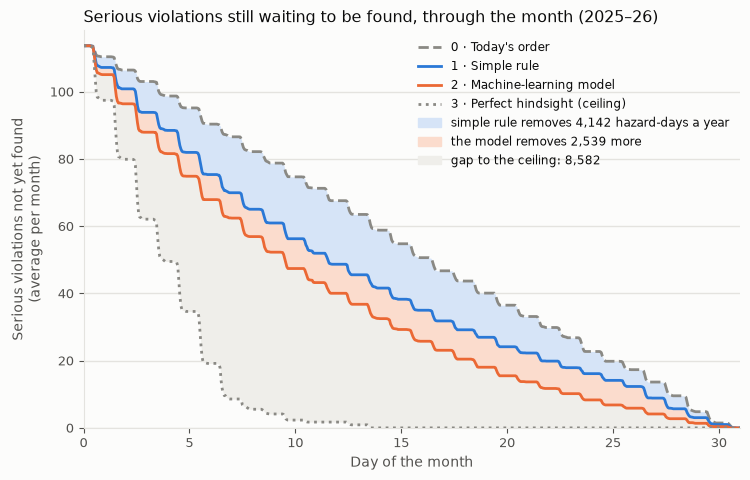

hazard-days per average month: {'today': '1,700', 'rule': '1,355', 'ml': '1,143', 'ceiling': '428'}


In [4]:
grid = np.linspace(0, 31, 621)
curve = {k: np.array([(DAYS[k].day.to_numpy() > d).sum() for d in grid]) / MONTHS for k, _ in TIERS}
area = {k: np.trapezoid(curve[k], grid) for k, _ in TIERS}      # hazard-days per average month
check('A2', 'area under each curve equals the hazard-days counted directly',
      all(abs(area[k] - monthly[f'days_{k}'].mean()) < 0.5 for k, _ in TIERS),
      ', '.join(f'{k}: {area[k]:,.0f}' for k, _ in TIERS))

STYLE = {
    'light': dict(surface='#fcfcfb', ink='#0b0b0b', muted='#52514e', grid='#e4e3df', rule='#2a78d6', model='#eb6834', ref='#8a8984',
                  band_rule='#d6e4f7', band_model='#fbdccd', band_rest='#efeeea'),
    'dark':  dict(surface='#1a1a19', ink='#f0efec', muted='#c3c2b7', grid='#33332f', rule='#3987e5', model='#d95926', ref='#8f8e88',
                  band_rule='#1f3350', band_model='#4a2a1c', band_rest='#2a2a28'),
}
per_year_days = {k: monthly[f'days_{k}'].sum() * PER_YEAR for k, _ in TIERS}
saved = {k: per_year_days['today'] - per_year_days[k] for k, _ in TIERS}

def draw(mode, path=None, show=False):
    c = STYLE[mode]
    fig, ax = plt.subplots(figsize=(7.6, 4.9), facecolor=c['surface'])
    ax.set_facecolor(c['surface'])
    ax.fill_between(grid, curve['rule'], curve['today'], color=c['band_rule'], lw=0, zorder=1)
    ax.fill_between(grid, curve['ml'], curve['rule'], color=c['band_model'], lw=0, zorder=1)
    ax.fill_between(grid, curve['ceiling'], curve['ml'], color=c['band_rest'], lw=0, zorder=1)
    for k, label, color, ls in [('today', "0 · Today's order", c['ref'], '--'), ('rule', '1 · Simple rule', c['rule'], '-'),
                                ('ml', '2 · Machine-learning model', c['model'], '-'), ('ceiling', '3 · Perfect hindsight (ceiling)', c['ref'], ':')]:
        ax.plot(grid, curve[k], ls, color=color, lw=2, label=label, zorder=3)
    ax.set(xlim=(0, 31), ylim=(0, max(curve['today']) * 1.04))
    ax.set_xlabel('Day of the month', color=c['muted'])
    ax.set_ylabel('Serious violations not yet found\n(average per month)', color=c['muted'])
    ax.set_title('Serious violations still waiting to be found, through the month (2025–26)', color=c['ink'], loc='left', fontsize=11.5)
    ax.yaxis.grid(True, color=c['grid'], lw=1)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(c['grid'])
    ax.tick_params(colors=c['muted'], labelsize=9)
    bands = [plt.matplotlib.patches.Patch(color=c['band_rule'], label=f"simple rule removes {saved['rule']:,.0f} hazard-days a year"),
             plt.matplotlib.patches.Patch(color=c['band_model'], label=f"the model removes {saved['ml'] - saved['rule']:,.0f} more"),
             plt.matplotlib.patches.Patch(color=c['band_rest'], label=f"gap to the ceiling: {saved['ceiling'] - saved['ml']:,.0f}")]
    lines, _ = ax.get_legend_handles_labels()
    leg = ax.legend(handles=lines + bands, frameon=False, loc='upper right', fontsize=8.5)
    for label in leg.get_texts():
        label.set_color(c['ink'])
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, facecolor=c['surface'])
    if show:
        plt.show()
    plt.close(fig)

for mode in STYLE:
    draw(mode, config.FIGURES / f'readme_impact_tiers_{mode}.png', show=(mode == 'light'))
print('hazard-days per average month:', {k: f'{area[k]:,.0f}' for k, _ in TIERS})

## 4 · The impact table, with confidence intervals

All measures per year. Intervals resample the 22 test months (2,000 draws), so they reflect month-to-month variation in which places were due and what they were found to have.

- **Hazards found in the first half:** inspections finding a Priority violation that fall in the first half of the month.
- **Hazard-days avoided:** days of uncorrected Priority violations removed relative to today's order (A2, A3).
- **Days earlier per hazard:** the average gain for each hazard.
- **Share of the possible gain:** the tier's hazard-days avoided as a share of the ceiling's.
- **Capacity equivalent:** how many more first-half inspections today's order would need to find as many hazards early, at its own first-half hit rate. This is a way to express the gain in staff terms, not a proposal to add inspections.

In [5]:
idx = np.random.default_rng(config.SEED).integers(0, MONTHS, size=(N_BOOT, MONTHS))
M = monthly.to_numpy(dtype=float)
col = {c: i for i, c in enumerate(monthly.columns)}
boot = lambda c: M[idx, col[c]].sum(axis=1) * PER_YEAR          # per-year totals in each draw

today_rate = monthly.early_today.sum() / (monthly.visits // 2).sum()
first_half_visits = (monthly.visits // 2).sum() * PER_YEAR

def ci(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return f'[{lo:,.0f}, {hi:,.0f}]'

table = {}
for k, name in TIERS:
    early, early_b = monthly[f'early_{k}'].sum() * PER_YEAR, boot(f'early_{k}')
    gain_b = early_b - boot('early_today')
    days_b = boot('days_today') - boot(f'days_{k}')
    table[name] = {'hazards found in the first half': early,
                   'more than today': early - monthly.early_today.sum() * PER_YEAR, '95% CI (more than today)': ci(gain_b) if k != 'today' else '—',
                   'hazard-days avoided': saved[k], '95% CI (hazard-days)': ci(days_b) if k != 'today' else '—',
                   'days earlier per hazard': saved[k] / (monthly.hazards.sum() * PER_YEAR),
                   'share of the possible gain': saved[k] / saved['ceiling'],
                   'capacity equivalent (inspections)': (early - monthly.early_today.sum() * PER_YEAR) / today_rate}
impact = pd.DataFrame(table).T
print(f'per year: {len(te) * PER_YEAR:,.0f} routine inspections ({first_half_visits:,.0f} in first halves), '
      f'{te.hit.sum() * PER_YEAR:,.0f} find a Priority violation; today finds {today_rate:.1%} of first-half visits with one')
impact.style.format({'hazards found in the first half': '{:,.0f}', 'more than today': '{:+,.0f}', 'hazard-days avoided': '{:,.0f}',
                     'days earlier per hazard': '{:.1f}', 'share of the possible gain': '{:.0%}', 'capacity equivalent (inspections)': '{:,.0f}'})

per year: 6,108 routine inspections (3,052 in first halves), 1,364 find a Priority violation; today finds 23.2% of first-half visits with one


,hazards found in the first half,more than today,95% CI (more than today),hazard-days avoided,95% CI (hazard-days),days earlier per hazard,share of the possible gain,capacity equivalent (inspections)
0 · Today,709,+0,—,0,—,0.0,0%,0
1 · Simple rule,925,+216,"[159, 266]","4,142","[3,233, 4,994]",3.0,27%,930
2 · Machine learning,"1,017",+308,"[259, 357]","6,682","[5,695, 7,667]",4.9,44%,"1,327"
3 · Ceiling,"1,364",+656,"[584, 726]","15,263","[13,791, 16,826]",11.2,100%,"2,824"


**Machine learning compared with the simple rule:** the increment this project adds over a rule a city could adopt without any model.

In [6]:
inc = {'hazards found in the first half': (boot('early_ml') - boot('early_rule'), (monthly.early_ml - monthly.early_rule).sum() * PER_YEAR),
       'hazard-days avoided': (boot('days_rule') - boot('days_ml'), (monthly.days_rule - monthly.days_ml).sum() * PER_YEAR)}
inc_t = pd.DataFrame({name: {'per year': est, '95% CI': ci(b), 'share of draws above zero': (b > 0).mean()} for name, (b, est) in inc.items()}).T
better = (monthly.early_ml > monthly.early_rule).sum()
worse = (monthly.early_ml < monthly.early_rule).sum()
sign = binomtest(better, better + worse, 0.5, alternative='greater')
print(f'months in which the model found more hazards in the first half than the rule: {better} of {MONTHS} '
      f'(fewer: {worse}, ties: {MONTHS - better - worse}); one-sided sign test p = {sign.pvalue:.4f}')
inc_t.style.format({'per year': '{:,.0f}', 'share of draws above zero': '{:.1%}'})

months in which the model found more hazards in the first half than the rule: 20 of 22 (fewer: 2, ties: 0); one-sided sign test p = 0.0001


,per year,95% CI,share of draws above zero
hazards found in the first half,92,"[70, 115]",100.0%
hazard-days avoided,"2,539","[2,176, 2,918]",100.0%


**Sensitivity of the hazard-days to A2.** If hazards can appear mid-month, an earlier visit might come before the hazard exists. Re-ordering only within two-week blocks (days 1–15 and 16–end) caps how far any visit moves, a conservative lower bound on hazard-days. The simpler model (b) without the comment score is shown too.

In [7]:
te['period_2wk'] = te.month + np.where(te.visit_ts.dt.day <= 15, '·a', '·b')
sens = {}
for label, period in [('monthly lists (main)', 'month'), ('two-week lists (conservative)', 'period_2wk')]:
    d = {k: found_days(te, k, period).day.sum() * PER_YEAR for k in ['today', 'rule', 'ml', 'model_b', 'ceiling']}
    sens[label] = {'simple rule': d['today'] - d['rule'], 'machine learning': d['today'] - d['ml'],
                   'model (b) alone': d['today'] - d['model_b'], 'ceiling': d['today'] - d['ceiling']}
sens = pd.DataFrame(sens).T
print('hazard-days avoided per year')
sens.style.format('{:,.0f}')

hazard-days avoided per year


,simple rule,machine learning,model (b) alone,ceiling
monthly lists (main),"4,142","6,682","6,533","15,263"
two-week lists (conservative),"2,321","3,444","3,410","7,692"


**Reading §3–§4.**
- **Scale.** A year has about 6,100 routine inspections. About 1,360 of them find a Priority violation, and today's order reaches about 710 of those in the first half of the month: half, as chance would.
- **Tier 1, the simple rule:** about 216 more hazards found in the first half [159, 266], each about 3 days sooner, so about **4,100 hazard-days a year removed** [3,200, 5,000]. That is 27% of what perfect hindsight could remove.
- **Tier 2, machine learning:** about 308 more hazards found early [259, 357], each about 5 days sooner, so about **6,700 hazard-days a year** [5,700, 7,700], or 44% of the possible gain.
  - Relative to today, it finds **43% more hazards in the first half** (rule: 30%).
  - To find as many hazards early, today's order would need about **1,330 more first-half inspections a year**, roughly a fifth of the annual routine workload. The ranking gets this with no extra inspections.
- **Tier 3, the ceiling:** about 15,300 hazard-days a year. More than half of the possible gain (56%) is beyond the model. Much of it comes from violations at places with clean histories, which past inspections give no reason to visit first (notebook 03).
- **The model's increment over the rule is robust:**
  - 92 more hazards found early a year [70, 115], and 2,540 hazard-days [2,180, 2,920];
  - positive in every one of the 2,000 resampled years;
  - the model beat the rule in **20 of the 22 test months** (sign test p = 0.0001).
- **Sensitivity (A2).** If visits may move only within two-week blocks, every tier's hazard-days roughly halve (rule 2,300, model 3,400, ceiling 7,700). The ordering of the tiers and the model's share stay the same. Model (b) without the comment score removes 6,500 hazard-days, within 2% of the primary model.

## 5 · Where the gain lands: by license type and by year

In [8]:
seg = {}
for name, e in [('sit-down (FS)', te[te.category == 'FS']), ('take-out (FT)', te[te.category == 'FT']), ('retail (RF)', te[te.category == 'RF']),
                ('2025', te[te.visit_ts.dt.year == 2025]), ('2026 (Jan–Oct)', te[te.visit_ts.dt.year == 2026])]:
    scale = 12 / e.month.nunique()
    row = {'routine inspections a year': len(e) * scale, 'hazards a year': e.hit.sum() * scale}
    for k, short in [('rule', 'rule'), ('ml', 'model'), ('ceiling', 'ceiling')]:
        row[f'hazard-days avoided · {short}'] = (found_days(e, 'today').day.sum() - found_days(e, k).day.sum()) * scale
    row['model share of the possible gain'] = row['hazard-days avoided · model'] / row['hazard-days avoided · ceiling']
    seg[name] = row
seg = pd.DataFrame(seg).T
seg.style.format({c: '{:,.0f}' for c in seg.columns} | {'model share of the possible gain': '{:.0%}'})

,routine inspections a year,hazards a year,hazard-days avoided · rule,hazard-days avoided · model,hazard-days avoided · ceiling,model share of the possible gain
sit-down (FS),"2,714",731,"1,745","2,775","7,593",37%
take-out (FT),"2,581",530,"1,720","2,716","5,930",46%
retail (RF),814,103,438,661,"1,335",50%
2025,"6,216","1,248","4,990","7,409","14,639",51%
2026 (Jan–Oct),"5,978","1,504","3,126","5,809","16,013",36%


Re-ranking within a license type is not what the city would do (one list covers all types), so the segments here re-rank within their own group: they show where the method works, not an exact split of the citywide totals.

## 6 · Break-even: what the ranking would need to prevent

The ranking's costs are an analyst's time (A6), with no new inspections, staff or equipment. The question that can be answered without knowing how often a hazard makes someone ill: **how many foodborne illnesses per year would it have to prevent to cover that cost?**

In [9]:
first_year = (SETUP_HOURS + 12 * MONTHLY_HOURS) * HOURLY_COST
ongoing = 12 * MONTHLY_HOURS * HOURLY_COST
ml_days = saved['ml']
extra_days = saved['ml'] - saved['rule']
be = {}
for label, cost in COST_PER_CASE.items():
    be[label] = {'cost per case': cost,
                 'illnesses to break even, first year': first_year / cost, 'illnesses to break even, later years': ongoing / cost,
                 'hazard-days avoided per illness needed (later years, vs today)': ml_days / (ongoing / cost),
                 'hazard-days avoided per illness needed (model over rule)': extra_days / (ongoing / cost)}
print(f'cost of producing the list: first year ${first_year:,.0f}, later years ${ongoing:,.0f} '
      f'({SETUP_HOURS} h setup, {MONTHLY_HOURS} h a month, ${HOURLY_COST}/h)')
pd.DataFrame(be).T.style.format({'cost per case': '${:,.0f}', 'illnesses to break even, first year': '{:.1f}',
                                 'illnesses to break even, later years': '{:.1f}',
                                 'hazard-days avoided per illness needed (later years, vs today)': '{:,.0f}',
                                 'hazard-days avoided per illness needed (model over rule)': '{:,.0f}'})

cost of producing the list: first year $19,200, later years $7,200 (120 h setup, 6 h a month, $100/h)


,cost per case,"illnesses to break even, first year","illnesses to break even, later years","hazard-days avoided per illness needed (later years, vs today)",hazard-days avoided per illness needed (model over rule)
specified pathogens (ERS 2023),"$4,766",4.0,1.5,"4,423","1,681"
unspecified gastroenteritis (ERS 2023),$781,24.6,9.2,725,275


In [10]:
hours = [3, 6, 12, 24]
scale = pd.DataFrame({f'{h} h a month': {label: 12 * h * HOURLY_COST / cost for label, cost in COST_PER_CASE.items()} for h in hours})
print('illnesses a year to break even (later years), by monthly analyst time')
scale.style.format('{:.1f}')

illnesses a year to break even (later years), by monthly analyst time


,3 h a month,6 h a month,12 h a month,24 h a month
specified pathogens (ERS 2023),0.8,1.5,3.0,6.0
unspecified gastroenteritis (ERS 2023),4.6,9.2,18.4,36.9


**Reading §5–§6.**
- **The method works for every license type.**
  - The model captures 37% (sit-down), 46% (take-out) and 50% (retail) of the possible gain within each type.
  - Sit-down restaurants carry the most hazards, so they hold the largest absolute gain.
  - In 2026, hazards were more common (25% of visits). The model removed more hazard-days than in 2025 relative to the rule, but a smaller share of a larger possible gain.
- **The break-even bar is low.** Producing the list costs about $7,200 a year after a $12,000 setup (A6). At the USDA's 2023 average of $4,766 per foodborne illness, preventing **1.5 illnesses a year** covers it; at $781 for an unspecified case, 9 a year.
  - Put another way: the ranking pays for itself if about **one illness is prevented for every 4,400 hazard-days removed** (specified pathogens), or one per 700 (unspecified).
  - Even quadrupling the analyst time keeps the bar at 6 illnesses a year (specified pathogens).
- **What this does not show:** whether the bar is met. That needs a link from violations to illnesses, which the data does not contain. Measuring it would take a pilot that tracks complaints and outbreak reports.

## 7 · Dollar value

Two ways to put dollars on the result, with different standing:
- **(a) Inspector-capacity value: the main figure.** This is what it would cost to get the same early detection by adding inspections to today's order: the capacity equivalent of §4 times the cost of one inspection. It uses this project's data and the city's own public payroll, plus two judgment parameters that are varied. This is a *replacement-cost* value: capacity the department gains, not cash it saves, since no budget line shrinks.
- **(b) Illness scenarios: illustration only.** The value of illnesses prevented, at assumed illness rates per hazard-day. No data supports any particular rate, so these are scenarios, not estimates.

| # | Parameter | Central | Range | Type | Source |
|---|---|---|---|---|---|
| P1 | Pay of a health inspector: median total gross pay of full-year ISD "Health Inspector" staff (regular pay ≥ $55,000) | from data | — | E | City of Boston Employee Earnings Report 2025 (Analyze Boston), downloaded without names |
| P2 | Health inspector full-time equivalents: total regular pay of the title ÷ median full-year regular pay | from data | — | E | same |
| P3 | Benefits and overhead on top of pay | × 1.35 | 1.2–1.6 | J | typical public-sector loading |
| P4 | Share of inspectors' time spent on the restaurant and retail inspections in this data (the rest: mobile food, permits, events, complaints) | 75% | 50–100% | J | not published |
| P5 | Inspections a year: all 2025 visits (routine, follow-up, filed) to sit-down, take-out and retail establishments | from data | — | E | this project's visit table |

Cost of one inspection = P1 × P3 × P2 × P4 ÷ P5. A routine inspection takes longer than the average visit, which includes short follow-ups, so averaging over all visits understates its cost. That makes (a) conservative.

In [11]:

import json
manifest = json.loads((config.RAW / 'manifest.json').read_text())
pay = pd.read_csv(config.RAW / manifest['earnings_isd']['file'], thousands=',')
inspectors = pay[pay.TITLE.str.match(r'Health Inspector')]
full_year = inspectors[inspectors.REGULAR >= 55_000]
P1 = full_year['TOTAL GROSS'].median()
P2 = inspectors.REGULAR.sum() / full_year.REGULAR.median()
P5 = int((visits.visit_ts.dt.year == 2025).sum())
SCEN = {'low': (1.2, 0.50), 'central': (1.35, 0.75), 'high': (1.6, 1.00)}          # (P3, P4)
cost_per_inspection = {s: P1 * load * P2 * share / P5 for s, (load, share) in SCEN.items()}
print(f'P1 median total pay ${P1:,.0f} ({len(full_year)} full-year of {len(inspectors)} staff) · P2 {P2:.1f} FTE · '
      f'P5 {P5:,} inspections in 2025 ({P5 / P2:,.0f} per FTE a year)')
print('cost of one inspection:', {s: f'${c:,.0f}' for s, c in cost_per_inspection.items()})

capacity = impact['capacity equivalent (inspections)']
rows_v = {'1 · Simple rule': capacity['1 · Simple rule'], '2 · Machine learning': capacity['2 · Machine learning'],
          'machine learning over the simple rule': capacity['2 · Machine learning'] - capacity['1 · Simple rule'],
          '3 · Ceiling': capacity['3 · Ceiling']}
value = pd.DataFrame({name: {'capacity equivalent (inspections a year)': cap,
                             **{f'value a year · {s}': cap * c for s, c in cost_per_inspection.items()}} for name, cap in rows_v.items()}).T
cap_b = (boot('early_ml') - boot('early_today')) / today_rate
print(f"machine learning, central cost: 95% CI from month resampling ${np.percentile(cap_b, 2.5) * cost_per_inspection['central']:,.0f}"
      f" – ${np.percentile(cap_b, 97.5) * cost_per_inspection['central']:,.0f} a year")
value.style.format({'capacity equivalent (inspections a year)': '{:,.0f}'} | {f'value a year · {s}': '${:,.0f}' for s in SCEN})


P1 median total pay $90,113 (17 full-year of 20 staff) · P2 17.5 FTE · P5 11,978 inspections in 2025 (685 per FTE a year)
cost of one inspection: {'low': '$79', 'central': '$133', 'high': '$210'}
machine learning, central cost: 95% CI from month resampling $148,291 – $204,917 a year


,capacity equivalent (inspections a year),value a year · low,value a year · central,value a year · high
1 · Simple rule,930,"$73,416","$123,889","$195,775"
2 · Machine learning,"1,327","$104,747","$176,761","$279,325"
machine learning over the simple rule,397,"$31,331","$52,872","$83,550"
3 · Ceiling,"2,824","$222,842","$376,046","$594,246"


**(b) Illness scenarios.** Value of illnesses prevented = hazard-days removed × illnesses per hazard-day × cost per illness (A5). The three rates are placeholders spanning two orders of magnitude, from one illness per 5,000 hazard-days to one per 200. The break-even rate of §6 is shown for reference.

In [12]:

RATES = {'1 per 5,000 hazard-days': 1 / 5000, '1 per 1,000': 1 / 1000, '1 per 200': 1 / 200}
scen = {}
for label, days in [('machine learning vs today', saved['ml']), ('machine learning over the simple rule', saved['ml'] - saved['rule'])]:
    for rate_name, rate in RATES.items():
        row = {'illnesses prevented a year': days * rate}
        row |= {f'value a year · {k.split(" (")[0]}': days * rate * cost for k, cost in COST_PER_CASE.items()}
        scen[(label, rate_name)] = row
scen = pd.DataFrame(scen).T
be_rate = (ongoing / COST_PER_CASE['specified pathogens (ERS 2023)']) / saved['ml']
print(f'break-even (later years, specified-pathogen cost): one illness per {1 / be_rate:,.0f} hazard-days removed')
scen.style.format({'illnesses prevented a year': '{:,.1f}'} | {c: '${:,.0f}' for c in scen.columns if c.startswith('value')})


break-even (later years, specified-pathogen cost): one illness per 4,423 hazard-days removed


**Reading §7.**
- **One inspection costs about $133** (range $79–$210). That is the median health-inspector pay of about $90,000, loaded for benefits and overhead, spread over about 685 restaurant and retail inspections per inspector a year, at 75% of their time.
- **(a) Capacity value: what the ranking is worth in inspector time:**
  - **simple rule:** about **$124,000 a year** ($73,000–$196,000);
  - **machine learning:** about **$177,000 a year** ($105,000–$279,000 across the parameter ranges; $148,000–$205,000 from month-to-month variation at the central cost);
  - **the model's increment over the rule:** about **$53,000 a year** ($31,000–$84,000);
  - **perfect hindsight**, for scale: about $376,000.
- **Against a running cost of about $7,200 a year** (A6), the model's capacity value is about **25 times its cost** at the central estimate, and over 14 times at the low end. This is capacity, not cash: the same staff find more problems early, and no budget line shrinks.
- **(b) Illness scenarios.** At one illness per 5,000 hazard-days, the model's 6,700 hazard-days are worth $1,000–$6,000 a year; at one per 200, $26,000–$159,000. The break-even rate (one per 4,400 hazard-days at the specified-pathogen cost) sits at the low end of this range. No data says which rate is right, so these numbers illustrate the stakes; they are not a result.

## 8 · Findings

| Per year (test period 2025–26) | 0 · Today | 1 · Simple rule | 2 · Machine learning | 3 · Ceiling |
|---|---|---|---|---|
| Serious violations found in the first half of the month | 709 | 925 (+216) | **1,017 (+308)** | 1,364 (+656) |
| Hazard-days removed | 0 | 4,142 | **6,682** | 15,263 |
| Days earlier per serious violation | 0 | 3.0 | **4.9** | 11.2 |
| Share of the possible gain | 0% | 27% | **44%** | 100% |
| Extra first-half inspections today's order would need to match | 0 | 930 | **1,327** | 2,824 |
| Value of that inspector capacity (central; range) | — | $124k ($73k–$196k) | **$177k ($105k–$279k)** | $376k |

1. **The gain is large in operational terms.** With the same inspections, the ranking finds about 300 more serious violations a year in the first half of the month, 43% more than today, each about 5 days sooner, for **about 6,700 fewer days of uncorrected hazards a year**. Matching that with today's order would take about 1,330 extra inspections, a fifth of a year's routine workload.
2. **Most of it needs no model.** The simple rule delivers about 60–70% of the gain (62% of the hazard-days, 70% of the extra early finds). The model's increment, about 2,500 hazard-days and 90 violations found early a year, is consistent: positive in 20 of 22 months, with confidence intervals well clear of zero.
3. **A large gap to perfect hindsight remains,** 56% of the possible gain. Much of it comes from violations at places whose records give no warning, which an order based on past inspections cannot anticipate.
4. **The result is robust to the main assumption.** With two-week lists, the hazard-days roughly halve but the tiers keep their order and shares. The simpler model without comments gives the same result within 2%.
5. **In dollars, the ranking is worth about $177,000 a year in inspector capacity** ($105,000–$279,000), against a running cost of about $7,200: about 25 times its cost. The simple rule alone is worth about $124,000, and the model adds about $53,000 on top. This is capacity, valued at the city's own payroll, not cash saved.
6. **The health value is favourable but unproven.** The list pays for itself if it prevents about 1.5 foodborne illnesses a year (USDA cost per case). Illness scenarios range from a few thousand to over $150,000 a year, depending on a rate no data can supply. That is the question a pilot should measure.
7. **Checks passed:** notebook 05 reproduced exactly (R23); hazard-days agree with notebook 05's days earlier; the area under each curve equals the directly counted hazard-days.

## 9 · Experiment log

In [13]:
from datetime import date
log = impact.reset_index(names='experiment')[['experiment', 'hazards found in the first half', 'hazard-days avoided', 'days earlier per hazard',
                                               'share of the possible gain']]
log = log.rename(columns={'days earlier per hazard': 'days earlier', 'share of the possible gain': 'headroom captured'})
log['note'] = 'business impact per year, test period (monthly lists)'
log['params'] = log.apply(lambda r: f"hazards found early {r['hazards found in the first half']:,.0f}/yr; hazard-days avoided "
                                    f"{r['hazard-days avoided']:,.0f}/yr", axis=1)
log = log[['experiment', 'days earlier', 'headroom captured', 'note', 'params']]
log.insert(0, 'date', date.today().isoformat())
log.insert(1, 'notebook', '06_business_impact')
path = config.RESULTS / 'experiments.csv'
previous = pd.read_csv(path)
previous = previous[previous.notebook != '06_business_impact']       # re-running replaces this notebook's rows
pd.concat([previous, log], ignore_index=True).to_csv(path, index=False)
print(f'wrote {len(log)} rows for this notebook to {path.relative_to(config.ROOT)}')
pd.DataFrame(CHECKS)

wrote 4 rows for this notebook to results/experiments.csv


,risk,check,result,detail
0,R23,notebook 05 reproduced: Today's order,pass,0.2322
1,R23,notebook 05 reproduced: Rule 1 · previous insp...,pass,0.3029
2,R23,notebook 05 reproduced: Model (b) + text · pri...,pass,0.3332
3,R23,notebook 05 reproduced: Model (b) · secondary,pass,0.3305
4,R23,notebook 05 reproduced: Perfect hindsight,pass,0.4470
5,A3,every hazard is found within its month under e...,pass,
6,R23,hazard-days avoided agree with notebook 05's '...,pass,
7,A2,area under each curve equals the hazard-days c...,pass,"today: 1,700, rule: 1,355, ml: 1,143, ceiling:..."
